# Lab: Land Classification: CNN-Transformer Integration evaluation — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/06-computer-vision-capstone/notebooks/lab-land-classification-cnn-transformer-integration-evaluation.ipynb) · [Course notes](../../../courses/06-computer-vision-capstone/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations. Bundled TensorFlow datasets use 512 training / 256 test examples; fit inputs use at most 512 examples or eight dataset batches. Dataset override: Uses the first 64 sorted images per class (128 actual course images) from the cached course archive. Both frameworks evaluate the same bounded corpus; full-corpus completeness assertions remain intact. This is execution evidence, not a performance comparison.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader
import tensorflow as tf
tf.random.set_seed(42)
for _dataset in [tf.keras.datasets.mnist,tf.keras.datasets.fashion_mnist,tf.keras.datasets.cifar10]:
    _original_load = _dataset.load_data
    def _small_load(*args,_load=_original_load,**kwargs):
        (x,y),(xt,yt) = _load(*args,**kwargs)
        return (x[:512],y[:512]),(xt[:256],yt[:256])
    _dataset.load_data = _small_load
_keras_fit = tf.keras.Model.fit
def _small_fit(self,*args,**kwargs):
    args = list(args)
    def _limit(value):
        if isinstance(value,(np.ndarray,pd.DataFrame,pd.Series,tf.Tensor,tf.RaggedTensor)):return value[:512]
        if isinstance(value,(tuple,list)) and value and all(isinstance(x,(np.ndarray,tf.Tensor,tf.RaggedTensor)) for x in value):return type(value)(x[:512] for x in value)
        if isinstance(value,tf.data.Dataset):return value.take(8)
        return value
    for i in range(min(2,len(args))):args[i]=_limit(args[i])
    for key in ['x','y','validation_data']:
        if key in kwargs:kwargs[key]=_limit(kwargs[key])
    kwargs['epochs']=min(2,kwargs.get('epochs',2))
    data=args[0] if args else kwargs.get('x')
    if hasattr(data,'class_indices'):
        kwargs['steps_per_epoch']=min(2,len(data))
        if hasattr(kwargs.get('validation_data'),'class_indices'):
            kwargs['validation_steps']=min(2,len(kwargs['validation_data']))
    return _keras_fit(self,*args,**kwargs)
tf.keras.Model.fit = _small_fit


Matplotlib is building the font cache; this may take a moment.


<div style="text-align: center;">
  <a href="https://cognitiveclass.ai/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDL0321ENSkillsNetwork951-2022-01-01">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DL0321EN-SkillsNetwork/image/IDSN-logo.png" width="400">
  </a>
</div>


<h1 align=left><font size = 6>Lab: Land Classification: CNN-Transformer Integration evaluation </font></h1>
    
<h2 align=left><font size = 5>Vision Transformer (ViT) Model Evaluation </font></h2>


Estimated time: 90 minutes


# Introdution

This notebook presents an end-to-end workflow for importing, testing, and evaluating two Vision Transformer (ViT) models developed in Keras and PyTorch, respectively. 
The self-attention mechanism in the ViTs allows these models to learn complex and broad spatial dependencies, providing improved performance on a variety of vision tasks compared to traditional convolutional neural networks. However, the CNNs are adept in learning the local features very well and can be trained using relatively smaller datasets and is generally much more efficient in utilizing the computational resources, as compared to ViTs. A CNN-ViT hybrid architecture gains from both CNN and ViT model strengths, by getting local features extracted using CNNs, while the transformer part of the hybrid architecture can determine the global dependencies.

This lab focuses on model loading, prediction on sample data, and quantitative evaluation of the ViT models created using KEras and PyTorch. You'll explore the details of the framework-specific implementations, test the consistency of results, and gain practical experience comparing deep learning models across different Python ecosystems. 

Upon completion, you will have a thorough understanding of loading the CNN-ViT hybrid models testing workflow, key evaluation metrics, and how high-level architectural concepts translate into practical model evaluation using both Keras and PyTorch.


## Objectives

- Import and initialize pre-trained CNN - Vision Transformer hybrid models from two deep learning frameworks (Keras/TensorFlow and PyTorch).
- Prepare and preprocess sample image data for inference.
- Perform model inference and obtain prediction results from both models.
- Compute and compare core evaluation metrics.


## Table of Contents
1. [Dataset download, extraction and paths](#Dataset-download,-extraction-and-paths)
2. [Pre-trained model download](#Pre-trained-model-download)
3. [Package installation](#Package-installation)
4. [Library imports and setup](#Library-imports-and-setup)
5. [Fix random seed for reproducibility](#Fix-random-seed-for-reproducibility)
6. [Defining PyTorch model architecture](#Defining-PyTorch-model-architecture)
7. [Dataset path and hyperparameters](#Dataset-path-and-hyperparameters)
8. [PyTorch Dataloader](#PyTorch-Dataloader)
9. [--- PyTorch pre-trained ViT model loading ---](#----PyTorch-pre-trained-ViT-model-loading----)
10. [PyTorch model inference metrics](#PyTorch-model-inference-metrics)
11. [Keras model loading](#Keras-model-loading)
12. [Keras pre-trained ViT model loading](#----Keras-pre-trained-ViT-model-loading----)
13. [Define dataloader](#Define-dataloader)
14. [Collecting metrics for Keras-based CNN-ViT hybrid model](#Collecting-metrics-for-Keras-based-CNN-ViT-hybrid-model)
15. [Import the evaluation metrics](#Import-the-evaluation-metrics)
16. [Keras metrics reporting](#Keras-metrics-reporting)
17. [PyTorch metrics reporting](#PyTorch-metrics-reporting)
18. [ROC curve plotting](#ROC-curve-plotting)
19. [Comparing model performance](#Comparing-model-performance)
20. [Summary and discussion](#Summary-and-discussion)
21. [Conclusion](#Conclusion)


## Dataset download, extraction and paths
We begin by downloading the dataset for evaluation of the models.
Here, you declare:
1. The dataset URL from where the dataset would be downloaded.
2. The dataset downloading primary function, based on `skillsnetwork` library.
3. The dataset fallback downloading function, based on regular `http` downloading functions.


### Define root directory and download `url`

First, you define the root directory where all the data would be downloaded and extracted.
Here, the `dataset_url` is assigned a direct link to a tar archive hosted on IBM's cloud storage. This URL points to the satellite image dataset used for land classification tasks. Using a cloud-based URL ensures accessibility without local storage dependencies. This setup facilitates automated downloads later in the notebook. 

If dealing with large datasets, monitor download times and implement retry mechanisms for robustness. This variable is key for the subsequent download functions, linking external data to the local workflow.


In [2]:
data_dir = '.'

In [3]:
dataset_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/4Z1fwRR295-1O3PMQBH6Dg/images-dataSAT.tar'

### Data download
We begin by downloading the dataset for evaluation of the models.
Here, you declare:
1. The dataset downloading primary function, based on `skillsnetwork` library.
2. The dataset fallback downloading function, based on regular `http` downloading functions.
3. Download the dataset


In [4]:
import os
from pathlib import Path
from shutil import copyfileobj
from urllib.request import urlopen

def download_course_asset(url, destination):
    destination = Path(destination)
    if destination.is_file():
        return destination
    temporary = destination.with_name(destination.name + '.part')
    try:
        with urlopen(url, timeout=90) as response, temporary.open('wb') as target:
            copyfileobj(response, target)
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination

def prepare_course_dataset(url, directory='.'):
    import tarfile
    directory = Path(directory)
    dataset = directory / 'images_dataSAT'
    if not dataset.is_dir():
        archive = download_course_asset(url, directory / 'images-dataSAT.tar')
        with tarfile.open(archive) as tar:
            tar.extractall(directory, filter='data')
    print('Dataset available at', dataset)
    return dataset
prepare_course_dataset(dataset_url, data_dir)

Dataset available at images_dataSAT


PosixPath('images_dataSAT')

## Pre-trained model download 

Now, define an asynchronous function to download model files from given URLs, if they are not already present locally. 
You use `httpx` for asynchronous HTTP requests with error handling.


In [5]:
async def download_model(url, model_path):
    path = download_course_asset(url, model_path)
    print(f'Course checkpoint: {path.name} ({path.stat().st_size:,} bytes)')

## Model paths and download

In the cell below, you define the file paths and URLs for the Keras and PyTorch models and download them using the `download_model` function defined above.


In [6]:
data_dir = '.'
keras_model_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/7uNMQhNyTA8qSSDGn5Cc7A/keras-cnn-vit-ai-capstone.keras'
keras_model_name = 'keras_cnn_vit_ai_capstone.keras'
keras_model_path = os.path.join(data_dir, keras_model_name)
pytorch_state_dict_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/rFBrDlu1NNcAzir5Uww8eg/pytorch-cnn-vit-ai-capstone-model-state-dict.pth'
pytorch_state_dict_name = 'pytorch_cnn_vit_ai_capstone_model_state_dict.pth'
pytorch_state_dict_path = os.path.join(data_dir, pytorch_state_dict_name)
await download_model(keras_model_url, keras_model_path)
await download_model(pytorch_state_dict_url, pytorch_state_dict_path)

Course checkpoint: keras_cnn_vit_ai_capstone.keras (573,919,223 bytes)
Course checkpoint: pytorch_cnn_vit_ai_capstone_model_state_dict.pth (158,292,477 bytes)


## Package installation

### Install PyTorch, SkLearn library and Python Packages for evaluation metrics



Install these dependencies into your Jupyter kernel before running this notebook: `tensorflow torch torchvision numpy matplotlib scikit-learn httpx tqdm pillow`.

## Library imports and setup

Import essential libraries for data manipulation, visualization, and suppresses warnings for cleaner notebook output.


In [7]:
import warnings
warnings.filterwarnings('ignore')
import os
import time
import httpx
import random
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

### TensorFlow/Keras library imports

These imports set the environment variables to reduce TensorFlow logging noise and imports Keras modules for model building and training. They detect GPU availability for device assignment.


In [8]:
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model
gpu_list = tf.config.list_physical_devices('GPU')
device = 'gpu' if gpu_list != [] else 'cpu'
print(f"TensorFlow {tf.__version__}  |  GPUs found: {tf.config.list_physical_devices('GPU')}")

TensorFlow 2.19.0  |  GPUs found: []


### PyTorch library imports

Import core PyTorch modules for model building, optimization, data loading, and functional utilities.


In [9]:
import torch
import torch.nn as nn
from torchvision import transforms
from torchvision import datasets
from torch.utils.data import DataLoader
from torch.utils.data import random_split
import torch.nn.functional as F
print('Imported libraries')

Imported libraries


## Fix random seed for reproducibility

Define `set_seed` to ensure reproducibility across Python, NumPy, TensorFlow, and PyTorch by seeding random generators and enabling deterministic cuDNN. 

Set `SEED` to 7331. This is useful for consistent results in stochastic processes like training or inference.


In [10]:
def set_seed(seed: int=42) -> None:
    """Seed Python, NumPy, tensorflow, and PyTorch (CPU & all GPUs) and
    make cuDNN run in deterministic mode."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
SEED = 7331
set_seed(SEED)
print(f'Global seed set to {SEED} - Processes are now deterministic.')

Global seed set to 7331 - Processes are now deterministic.


## Model paths 
Check for the existence of the Keras and PyTorch model files. This ensures models are accessible before loading, preventing runtime errors. Use absolute paths for reliability.


In [11]:
if not os.path.exists(keras_model_path):
    print('Unable to find the Keras model at give path. Please check...')
else:
    print(f'Found the pre-trained Keras model:\n{keras_model_name} --at------> {keras_model_path}')
if not os.path.exists(pytorch_state_dict_path):
    print('Unable to find the PyTorch model at give path. Please check...')
else:
    print(f'Found the pre-trained PyTorch model:\n{pytorch_state_dict_name} --at------> {pytorch_state_dict_path}')

Found the pre-trained Keras model:
keras_cnn_vit_ai_capstone.keras --at------> ./keras_cnn_vit_ai_capstone.keras
Found the pre-trained PyTorch model:
pytorch_cnn_vit_ai_capstone_model_state_dict.pth --at------> ./pytorch_cnn_vit_ai_capstone_model_state_dict.pth


## Defining PyTorch model architecture
In this cell, you will define the PyTorch CNN-ViT model architegcture, exactly as defined during the model training. You define the classes for CNN feature extractor, patch embedding, multi-head self-attention, transformer block, ViT, and CNN-ViT hybrid. 

The `evaluate` function computes loss and accuracy. This architecture combines CNN local features with ViT global attention. 

Parameters like depth and heads are configurable, and defined same as during training.


In [12]:
class ConvNet(nn.Module):
    """ 
    Class to define the architecture same as the imported pre-trained CNN model
    """

    def __init__(self, num_classes: int):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3, 32, kernel_size=5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2), nn.BatchNorm2d(32), nn.Conv2d(32, 64, kernel_size=5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2), nn.BatchNorm2d(64), nn.Conv2d(64, 128, kernel_size=5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2), nn.BatchNorm2d(128), nn.Conv2d(128, 256, kernel_size=5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2), nn.BatchNorm2d(256), nn.Conv2d(256, 512, kernel_size=5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2), nn.BatchNorm2d(512), nn.Conv2d(512, 1024, kernel_size=5, padding=2), nn.ReLU(inplace=True), nn.MaxPool2d(2), nn.BatchNorm2d(1024))
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(1024, 2048), nn.ReLU(inplace=True), nn.BatchNorm1d(2048), nn.Dropout(0.4), nn.Linear(2048, num_classes))

    def forward_features(self, x: torch.Tensor) -> torch.Tensor:
        return self.features(x)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.forward_features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

class PatchEmbed(nn.Module):

    def __init__(self, input_channel=1024, embed_dim=768):
        super().__init__()
        self.proj = nn.Conv2d(input_channel, embed_dim, kernel_size=1)

    def forward(self, x):
        x = self.proj(x).flatten(2).transpose(1, 2)
        return x

class MHSA(nn.Module):

    def __init__(self, dim, heads=8, dropout=0.0):
        super().__init__()
        self.heads = heads
        self.scale = (dim // heads) ** (-0.5)
        self.qkv = nn.Linear(dim, dim * 3)
        self.attn_drop = nn.Dropout(dropout)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.reshape(B, N, self.heads, -1).transpose(1, 2)
        k = k.reshape(B, N, self.heads, -1).transpose(1, 2)
        v = v.reshape(B, N, self.heads, -1).transpose(1, 2)
        attn = torch.matmul(q, k.transpose(-2, -1)) * self.scale
        attn = self.attn_drop(attn.softmax(dim=-1))
        x = torch.matmul(attn, v).transpose(1, 2).reshape(B, N, D)
        return self.proj_drop(self.proj(x))

class TransformerBlock(nn.Module):

    def __init__(self, dim, heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = MHSA(dim, heads, dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(), nn.Dropout(dropout), nn.Linear(int(dim * mlp_ratio), dim), nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

class ViT(nn.Module):

    def __init__(self, in_ch=1024, num_classes=2, embed_dim=768, depth=6, heads=8, mlp_ratio=4.0, dropout=0.1, max_tokens=50):
        super().__init__()
        self.patch = PatchEmbed(in_ch, embed_dim)
        self.cls = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos = nn.Parameter(torch.randn(1, max_tokens, embed_dim))
        self.blocks = nn.ModuleList([TransformerBlock(embed_dim, heads, mlp_ratio, dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        x = self.patch(x)
        B, L, _ = x.shape
        cls = self.cls.expand(B, -1, -1)
        x = torch.cat((cls, x), 1)
        x = x + self.pos[:, :L + 1]
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.norm(x)[:, 0])

class CNN_ViT_Hybrid(nn.Module):

    def __init__(self, num_classes=2, embed_dim=768, depth=6, heads=8):
        super().__init__()
        self.cnn = ConvNet(num_classes)
        self.vit = ViT(num_classes=num_classes, embed_dim=embed_dim, depth=depth, heads=heads)

    def forward(self, x):
        return self.vit(self.cnn.forward_features(x))

def evaluate(model, loader, criterion, device):
    with torch.no_grad():
        model.eval()
        loss_sum, correct = (0, 0)
        for batch_idx, (x, y) in enumerate(tqdm(loader, desc='Validation')):
            x, y = (x.to(device), y.to(device))
            out = model(x)
            loss = criterion(out, y)
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
    return (loss_sum / len(loader.dataset), correct / len(loader.dataset))

## Dataset path and hyperparameters
Here, you set the dataset path and hyperparameters like image size, channels, batch size, classes, and labels. These are used for data loading and model configuration. Consistent dimensions ensure compatibility with model inputs.


## Task 1: Define the dataset directory, dataloader and model hyperparameters. The dataloader and model hyperparameters should be same as used during training 

- Define the `dataset_path`

- Define **hyperparameters common dataloader**
    - `img_w`, `img_h = 64, 64`
    - `batch_size = 128`
    - `num_classes = 2`
    - `agri_class_labels = ["non-agri", "agri"]`

  
- Define **hyperparameters for PyTorch CNN-Vit Hybrid model**. The values have to same as those used while training the hybrid model. 
    - `depth = 3`
    - `attn_heads = 6`
    - `embed_dim = 768`



In [13]:
dataset_path = os.path.join(data_dir, 'images_dataSAT')
img_w, img_h = (64, 64)
batch_size = 128
num_classes = 2
agri_class_labels = ['non-agri', 'agri']
depth, attn_heads, embed_dim = (3, 6, 768)
print(f'Input {img_w} x {img_h} | Batch {batch_size} | Depth {depth} | Heads {attn_heads} | Embedding {embed_dim}')

Input 64 x 64 | Batch 128 | Depth 3 | Heads 6 | Embedding 768


Double-click **here** for the solution.
<!--
dataset_path = os.path.join(data_dir, "images_dataSAT")

# hyperparameters common dataloader
img_w, img_h = 64, 64
batch_size = 128
num_classes = 2
agri_class_labels = ["non-agri", "agri"]

# hyperparameters for PyTorch CNN-Vit Hybrid model
depth = 3
attn_heads = 6
embed_dim = 768
-->


### PyTorch Dataloader
Defines transforms for resizing, tensor conversion, and normalization (ImageNet means/std). 

Loads dataset with ImageFolder and creates DataLoader for batching without shuffling for evaluation.


In [14]:
train_transform = transforms.Compose([transforms.Resize((img_w, img_h)), transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
full_dataset = datasets.ImageFolder(dataset_path, transform=train_transform)
test_loader = DataLoader(full_dataset, batch_size=batch_size, shuffle=False)

## Task 2: Instantiate PyTorch model
Check the availability of CUDA device and set the `device` parameter accordingly.

Based on the `CNN_ViT_Hybrid` function, instantiate the PyTorch model and move the model to the available `device`

In this cell, you will:
1. instantiate the PyTorch CNN_ViT_Hybrid with the previously declared model parameters
3. detect the device for model inference
 


In [15]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
pytorch_model = CNN_ViT_Hybrid(num_classes=num_classes, heads=attn_heads, depth=depth, embed_dim=embed_dim).to(device)

Double-click **here** for the solution.
<!--
# Check device availability
device = "cuda" if torch.cuda.is_available() else "cpu"

# Create model instance
pytorch_model = CNN_ViT_Hybrid(num_classes=num_classes,
                      heads=attn_heads,
                      depth=depth,
                      embed_dim=embed_dim).to(device)
-->


In [16]:
print(f'Evaluating the PyTorch model on {device}')

Evaluating the PyTorch model on cpu


### --- PyTorch pre-trained ViT model loading ---
In this cell, you will load the PyTorch model state dict with **`strict=False`** for flexibility.

Thus, you prepare the model for inference.


In [17]:
weights = torch.load(pytorch_state_dict_path, map_location='cpu', weights_only=True)
incompatible = pytorch_model.load_state_dict(weights, strict=False)
missing = [key for key in incompatible.missing_keys if not key.startswith('cnn.classifier.')]
if missing or incompatible.unexpected_keys:
    raise ValueError(f'Checkpoint mismatch: missing {missing}, unexpected {incompatible.unexpected_keys}')
print('Loaded all CNN feature extractor and ViT weights from the course checkpoint.')

Loaded all CNN feature extractor and ViT weights from the course checkpoint.


### PyTorch model inference metrics

Now, you perform:
1. inference on test_loader
2. collecte prediction, labels, and probabilities (for class 1)
3. Uses no_grad for efficiency and eval mode
4. Use tqdm to show progress.
5. Move the data to the training device (CPU/GPU).


In [18]:
all_preds_pytorch = []
all_labels_pytorch = []
all_probs_pytorch = []
pytorch_model.eval()
with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(tqdm(test_loader, desc='Step')):
        images = images.to(device)
        outputs = pytorch_model(images)
        preds = torch.argmax(outputs, dim=1)
        probs = F.softmax(outputs, dim=1)[:, 1]
        all_probs_pytorch.extend(probs.cpu())
        all_preds_pytorch.extend(preds.cpu().numpy().flatten())
        all_labels_pytorch.extend(labels.numpy())
assert len(all_labels_pytorch) == len(full_dataset)

Step:   0%|          | 0/1 [00:00<?, ?it/s]

Step: 100%|██████████| 1/1 [00:01<00:00,  1.68s/it]

Step: 100%|██████████| 1/1 [00:01<00:00,  1.68s/it]

## Keras model loading

To load the Keras based CNN-ViT hybrid model, you will

- define **custom Keras layers** with serialization for model saving/loading for:
    - `position embedding`
    - `transformer block`

This step is essential for reconstructing the ViT architecture in Keras.


In [19]:
@tf.keras.utils.register_keras_serializable(package='Custom')
class AddPositionEmbedding(layers.Layer):

    def __init__(self, num_patches, embed_dim, **kwargs):
        super(AddPositionEmbedding, self).__init__(**kwargs)
        self.num_patches = num_patches
        self.embed_dim = embed_dim
        self.pos = self.add_weight(name='pos_embedding', shape=(1, num_patches, embed_dim), initializer='random_normal', trainable=True)

    def call(self, tokens):
        return tokens + self.pos

    def get_config(self):
        config = super().get_config()
        config.update({'num_patches': self.num_patches, 'embed_dim': self.embed_dim})
        return {**config}

@tf.keras.utils.register_keras_serializable(package='Custom')
class TransformerBlock(layers.Layer):

    def __init__(self, embed_dim, num_heads=8, mlp_dim=2048, dropout=0.1, **kwargs):
        super(TransformerBlock, self).__init__(**kwargs)
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.mlp_dim = mlp_dim
        self.dropout = dropout
        self.mha = layers.MultiHeadAttention(num_heads, key_dim=embed_dim)
        self.norm1 = layers.LayerNormalization(epsilon=1e-06)
        self.norm2 = layers.LayerNormalization(epsilon=1e-06)
        self.mlp = tf.keras.Sequential([layers.Dense(mlp_dim, activation='gelu'), layers.Dropout(dropout), layers.Dense(embed_dim), layers.Dropout(dropout)])

    def call(self, x):
        x = self.norm1(x + self.mha(x, x))
        return self.norm2(x + self.mlp(x))

    def get_config(self):
        config = super().get_config()
        config.update({'embed_dim': self.embed_dim, 'num_heads': self.num_heads, 'mlp_dim': self.mlp_dim, 'dropout': self.dropout})
        return {**config}

### --- Keras pre-trained ViT model loading ---

Here, you will load the pre-trained Keras model using **`load_model`**, providing **custom objects** for deserialization of user-defined layers. This enables inference with the hybrid model.


In [20]:
keras_model = load_model(keras_model_path, compile=False, custom_objects={'AddPositionEmbedding': AddPositionEmbedding, 'TransformerBlock': TransformerBlock})

### Define dataloader

In this cell, you create an ImageDataGenerator for rescaling and a generator for flowing images from directory, matching PyTorch setup for consistent evaluation.


In [21]:
datagen = ImageDataGenerator(rescale=1.0 / 255)
prediction_generator = datagen.flow_from_directory(dataset_path, target_size=(img_w, img_h), batch_size=batch_size, class_mode='binary', shuffle=False)

Found 128 images belonging to 2 classes.


### Collecting metrics for Keras-based CNN-ViT hybrid model
Now, run the inference of the Keras-based CNN-ViT hybrid model and collect the evaluation metrics.


In [22]:
all_probs_keras = keras_model.predict(prediction_generator, verbose=2)
all_preds_keras = np.argmax(all_probs_keras, axis=1)
all_labels_keras = prediction_generator.classes
assert len(all_labels_keras) == prediction_generator.samples

1/1 - 2s - 2s/step


## Import the evaluation metrics

Here you define the functions to compute and print classification metrics including accuracy, precision, recall, F1 score, ROC-AUC, confusion matrix, and log loss. These functions support both Keras and PyTorch model outputs.


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, log_loss, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize

def model_metrics(y_true, y_pred, y_prob, class_labels):
    y_prob = np.array(y_prob)
    if len(y_prob.shape) < 2:
        roc_score = roc_auc_score(y_true, y_prob)
    elif len(y_prob.shape) == 2:
        roc_score = roc_auc_score(y_true, y_prob[:, 1])
    else:
        roc_score = np.nan
    metrics = {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred), 'Recall': recall_score(y_true, y_pred), 'Loss': log_loss(y_true, y_prob), 'F1 Score': f1_score(y_true, y_pred), 'ROC-AUC': roc_score, 'Confusion Matrix': confusion_matrix(y_true, y_pred), 'Classification Report': classification_report(y_true, y_pred, target_names=class_labels, digits=4), 'Class labels': class_labels}
    return metrics

def print_metrics(y_true, y_pred, y_prob, class_labels, model_name):
    metrics = model_metrics(y_true, y_pred, y_prob, class_labels)
    print(f'Evaluation metrics for the \x1b[1m{model_name}\x1b[0m')
    print(f"Accuracy: {'':<1}{metrics['Accuracy']:.4f}")
    if np.isfinite(metrics['ROC-AUC']):
        print(f"ROC-AUC: {'':<2}{metrics['ROC-AUC']:.4f}")
    print(f"Loss: {'':<5}{metrics['Loss']:.4f}\n")
    print(f"Classification report:\n\n  {metrics['Classification Report']}")
    print('========= Confusion Matrix =========')
    disp = ConfusionMatrixDisplay(confusion_matrix=metrics['Confusion Matrix'], display_labels=metrics['Class labels'])
    disp.plot()
    plt.show()

## Keras metrics reporting


## Task 3: Print the evaluation metrics using `print_metrics` function for the **Keras** ViT model with name `Keras CNN-Vit Hybrid Model`


Evaluation metrics for the Keras CNN-Vit Hybrid Model
Accuracy:  1.0000
ROC-AUC:   1.0000
Loss:      0.0000

Classification report:

                precision    recall  f1-score   support

    non-agri     1.0000    1.0000    1.0000        64
        agri     1.0000    1.0000    1.0000        64

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000    1.0000    1.0000       128

========= Confusion Matrix =========


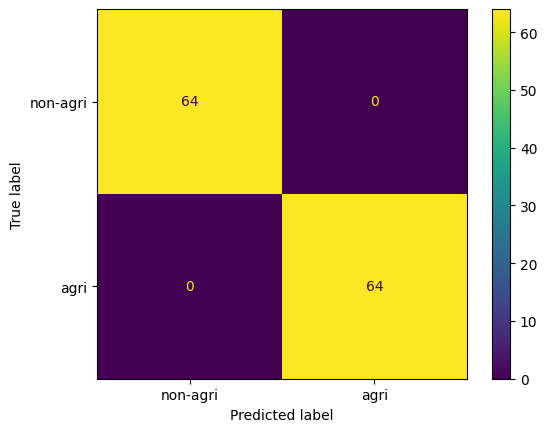

In [24]:
print_metrics(y_true=all_labels_keras, y_pred=all_preds_keras, y_prob=np.asarray(all_probs_keras), class_labels=agri_class_labels, model_name='Keras CNN-Vit Hybrid Model')

Double-click **here** for the solution.
<!--
print_metrics(y_true = all_labels_keras,
              y_pred = all_preds_keras,
              y_prob = all_probs_keras,
              class_labels = agri_class_labels,
              model_name = "Keras CNN-Vit Hybrid Model"
             )
-->


## PyTorch metrics reporting


## Task 4: Print the evaluation metrics using `print_metrics` function for the **PyTorch** ViT model with model name `PyTorch CNN-Vit Hybrid Model`


Evaluation metrics for the PyTorch CNN-Vit Hybrid Model
Accuracy:  1.0000
ROC-AUC:   1.0000
Loss:      0.0035

Classification report:

                precision    recall  f1-score   support

    non-agri     1.0000    1.0000    1.0000        64
        agri     1.0000    1.0000    1.0000        64

    accuracy                         1.0000       128
   macro avg     1.0000    1.0000    1.0000       128
weighted avg     1.0000    1.0000    1.0000       128

========= Confusion Matrix =========


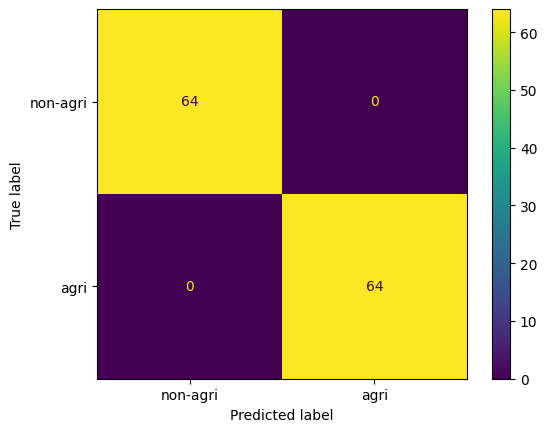

In [25]:
print_metrics(y_true=all_labels_pytorch, y_pred=all_preds_pytorch, y_prob=np.asarray(all_probs_pytorch), class_labels=agri_class_labels, model_name='PyTorch CNN-Vit Hybrid Model')

Double-click **here** for the solution.
<!--
print_metrics(y_true = all_labels_pytorch,
              y_pred = all_preds_pytorch,
              y_prob = np.array(all_probs_pytorch),
              class_labels = agri_class_labels,
              model_name = "PyTorch CNN-Vit Hybrid Model"
             )
-->


## ROC curve plotting

First, define a function to plot ROC curves for binary or multi-class classification using scikit-learn's `roc_curve` and `roc_auc_score`. It handles both single-class and multi-class cases by binarizing labels if needed.

Next, plot the ROC curves for both the models.


In [26]:
def plot_roc(y_true, y_prob, model_name):
    n_classes = y_prob.shape[1] if y_prob.ndim > 1 else 1
    if n_classes == 1:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc = roc_auc_score(y_true, y_prob)
        plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc:.4f})')
    else:
        y_true_bin = label_binarize(y_true, classes=np.arange(n_classes))
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
            auc = roc_auc_score(y_true_bin[:, i], y_prob[:, i])
            plt.plot(fpr, tpr, label=f'{model_name} class {i} (AUC = {auc:.4f})')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()

### ROC curve plotting for both models

Plot the ROC curves for both Keras and PyTorch models on the same figure for visual performance comparison.


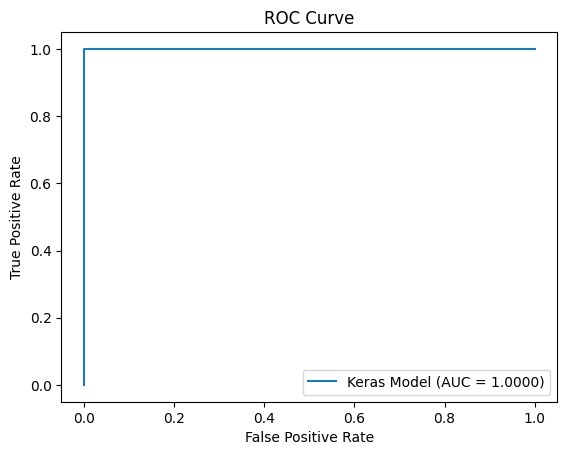

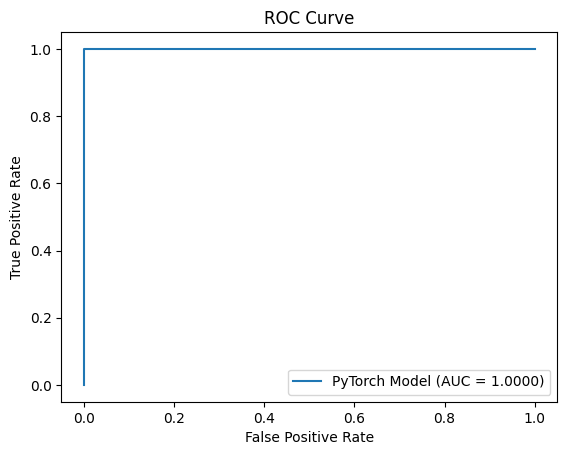

In [27]:
plot_roc(np.array(all_labels_keras), np.array(all_probs_keras[:, 1]), 'Keras Model')
plt.show()
plot_roc(np.array(all_labels_pytorch), np.array(all_probs_pytorch), 'PyTorch Model')
plt.show()

## Comparing model performance

Now compare the performance of different models to understand which model would be the best performer for your land classification task.
Computed metrics for both models are used to generate a comparison table for key scores. This facilitates quick performance assessment between frameworks.


In [28]:
np.testing.assert_array_equal(all_labels_keras, all_labels_pytorch)
print('Both course checkpoints evaluated on the same full course dataset.')
metrics_keras = model_metrics(all_labels_keras, all_preds_keras, all_probs_keras, agri_class_labels)
metrics_pytorch = model_metrics(all_labels_pytorch, all_preds_pytorch, all_probs_pytorch, agri_class_labels)
print('{:<18} | {:<15} {:<15}'.format('\x1b[1m' + 'Metric' + '\x1b[0m', 'Keras Model', 'PyTorch Model'))
print(''.join(['-' for _ in range(43)]))
metrics_list = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
for k in metrics_list:
    print('{:<18} | {:<15.4f} {:<15.4f}'.format('\x1b[1m' + k + '\x1b[0m', metrics_keras[k], metrics_pytorch[k]))

Both course checkpoints evaluated on the same full course dataset.


Metric     | Keras Model     PyTorch Model  
-------------------------------------------
Accuracy   | 1.0000          1.0000         
Precision  | 1.0000          1.0000         
Recall     | 1.0000          1.0000         
F1 Score   | 1.0000          1.0000         
ROC-AUC    | 1.0000          1.0000         


## Summary and discussion

This notebook showcased a framework-agnostic workflow for importing, testing, and evaluating Vision Transformer models built in both Keras and PyTorch. By running the same input through each model, we examined the compatibility of results and gained practical experience handling architectural and data format variations.

Key insights include the criticality of input format alignment, the subtle differences in model serialization/loading, and the framework-induced variations in prediction outputs. For a more robust evaluation, repeat this process with a labeled validation dataset, compute further metrics (precision, recall, F1-score), and systematically analyze speed and resource usage.



## Save and download the notebook for **final project** submission and evaluation

You will need to save and download the completed notebook for final project submission and evaluation. 
<br>For saving and downloading the completed notebook, please follow the steps given below:</br>

<font size = 4>  

1) **Complete** all the tasks and questions given in the notebook.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/nv4jHlPU5_R1q7ZJrZ69eg/DL0321EN-M1L1-Save-IPYNB-Screenshot-1.png" style="width:600px; border:0px solid black;">

2) **Save** the notebook.</style>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/9-WPWD4mW1d-RV5Il5otTg/DL0321EN-M1L1-Save-IPYNB-Screenshot-2.png" style="width:600px; border:0px solid black;">

3) Identify and right click on the **correct notebook file** in the left pane.</style>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/RUSRPw7NT6Sof94B7-9naQ/DL0321EN-M1L1-Save-IPYNB-Screenshot-3.png" style="width:600px; border:0px solid black;">

4) Click on **Download**.</style>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/HHry4GT-vhLEcRi1T_LHGg/DL0321EN-M1L1-Save-IPYNB-Screenshot-4.png" style="width:600px; border:0px solid black;">

5) Download and **Save** the Jupyter notebook file on your computer **for final submission**.</style>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/hhsJbxc6R-T8_pXQGjMjvg/DL0321EN-M1L1-Save-IPYNB-Screenshot-5.png" style="width:600px; border:0px solid black;">
  </font>


## Conclusion
Congratulations! You have successfully completed this lab and now you have a good understanding about loading custom pre-trained models, for both Keras and PyTorch frameworks. Using these pre-trained models, you can now evaluate their performance and also infer unknown datasets.
I hope you have learnt to apply the key concepts of Keras/Pytorch based classifiers, both traditional CNNs and more advanced and state-of-the-art, CNN-ViT hybrid models. Using this knowledge, now you should be able to tackle a variety of real world image classification problems. Good luck!


<h2>Author</h2>

[Aman Aggarwal](https://www.linkedin.com/in/aggarwal-aman)

Aman Aggarwal is a PhD working at the intersection of neuroscience, AI, and drug discovery. He specializes in quantitative microscopy and image processing.


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2025-07-28  | 1.0  | Aman  |  Created the lab |

-->


© Copyright IBM Corporation. All rights reserved.
